# Primary outcomes of behavioral chronic-pain trials: analysis

**Rebuilt automatically** by `finalize_cohort` (or alone: `PYTHONPATH=src python -m ctgov_pipeline.run_analysis`). Every figure is also saved to `analysis/figures/` (PNG 300 dpi + PDF) and the tables behind them to `analysis/tables/` (CSV), so this notebook is the single source of the article's figures. Do not edit the saved files by hand; change the code and rebuild.

Research question: among behavioral interventions for chronic pain (back pain, fibromyalgia, migraine, headache), which primary outcomes do researchers register, and how does this differ by intervention approach and over time?

Sections: **1** trials over time, **2** cohort summary table, **3** exclusion reasons, **4** conditions, **5** interventions, **6** intervention x outcome cross-tab (with filters), then additional views.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "analysis" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from ctgov_pipeline import analysis_data as ad
from ctgov_pipeline import analysis_plots as ap

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
ap.set_style()

studies, outcomes = ad.load_tables()
LABELS = ad.intervention_labels()
inc = ad.included(studies)


def show(fig, name):
    """Save the figure to analysis/figures/<name>.png|pdf and show it here."""
    ap.save_figure(fig, name)
    display(fig)
    plt.close(fig)


print(f"Extraction run {studies['extraction_run_id'].iloc[0]}, rules {studies['cohort_rules_version'].iloc[0]}: "
      f"{len(studies)} trials in the pool, {len(inc)} included, "
      f"{(outcomes['cohort_inclusion_status'] == 'included').sum()} primary-outcome rows in included trials.")

Extraction run full_20261109_104453, rules conditions_field_v3: 936 trials in the pool, 824 included, 1900 primary-outcome rows in included trials.


## 1. Trials over time

Included trials per year of first posting on ClinicalTrials.gov (excluded trials in grey on top, so the growth of the whole pool is visible too). Registration volume grows strongly after 2015; the latest year is partial.

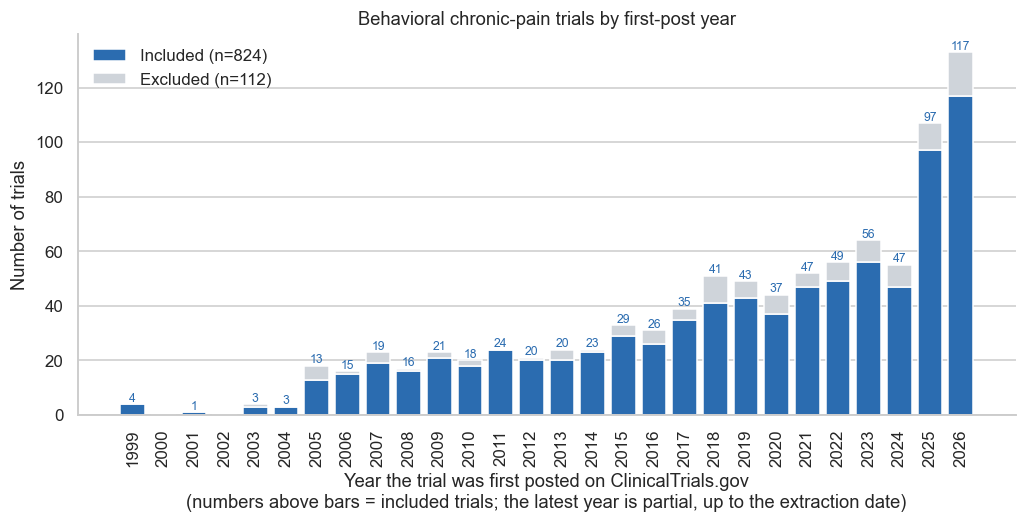

In [2]:
show(ap.plot_trials_by_year(studies), "fig01_trials_by_year")
yearly = studies.groupby(["first_post_year", "cohort_inclusion_status"]).size().unstack(fill_value=0)
ap.save_table(yearly, "tab01_trials_by_year")

## 2. Cohort summary table

Means and shares of "studies with more than one primary outcome" use the included trials that registered at least one primary outcome as denominator.

In [3]:
summary = ad.cohort_summary_table(studies, outcomes)
ap.save_table(summary, "tab02_cohort_summary", index=False)
display(summary.style.hide(axis="index"))

Metric,Value,Note
Master pool (before filtering),936,all trials retrieved from CT.gov
Final analytic cohort,824,88.0% of the pool
Excluded,112,12.0% of the pool
Primary outcome rows (included trials),"1,900",one row per registered primary outcome
Studies with more than one primary outcome,382,47.1% of the 811 included trials with a registered primary outcome
Mean primary outcomes per study,2.34,over the 811 included trials with a registered primary outcome
Multimodal intervention trials,101,12.3% of included (behavioral + an active non-behavioral arm)
Included trials with no registered primary outcome,13,no row in primary_outcomes.csv


## 3. Exclusion reasons

Each excluded trial is counted once, under the first rule that matched (`docs/COHORT_FILTERING_RULES.md`). Two strata, as stored in `exclusion_reason`: **condition eligibility** (the registered conditions or the population do not fit: cancer, other pathology, pregnancy, no target condition, subacute/perioperative, not about pain) and **pain-character eligibility** (acute pain, or a stated pain duration of 11 weeks or less).

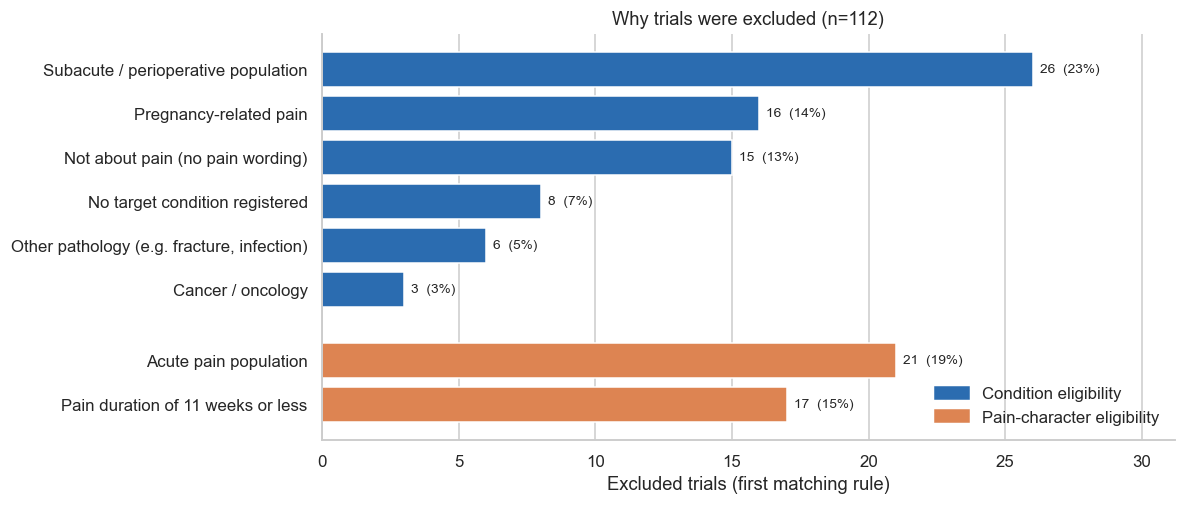

exclusion_stratum,exclusion_rule,trials
Condition eligibility,cancer_oncology,3
Condition eligibility,no_target_match,8
Condition eligibility,not_about_pain,15
Condition eligibility,pathology_other,6
Condition eligibility,pregnancy_related,16
Condition eligibility,subacute_perioperative,26
Pain-character eligibility,acute_pain,21
Pain-character eligibility,short_pain_window,17


In [4]:
show(ap.plot_exclusion_reasons(studies), "fig03_exclusion_reasons")
exclusions = (studies[studies["cohort_inclusion_status"] == "excluded"]
              .groupby(["exclusion_stratum", "exclusion_rule"]).size().rename("trials").reset_index())
ap.save_table(exclusions, "tab03_exclusion_reasons", index=False)
display(exclusions.style.hide(axis="index"))

## 4. Trials per pain condition

A condition counts when it is among the trial's **registered conditions** (the cohort filter). Many trials list more than one, so the left panel does not sum to the cohort size; the right panel counts every trial once by its exact combination. "Headache (other types)" means headache types other than plain migraine.

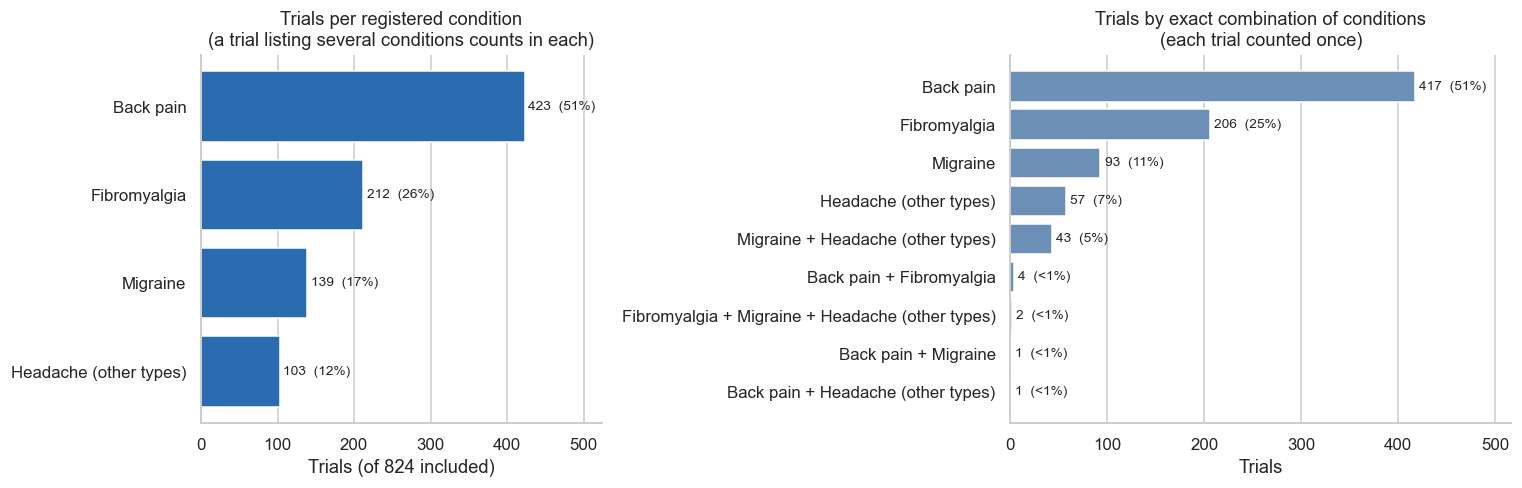

,trials,share_of_included
Back pain,423,0.513
Fibromyalgia,212,0.257
Migraine,139,0.169
Headache (other types),103,0.125


In [5]:
show(ap.plot_conditions(studies), "fig04_conditions")
cond = pd.DataFrame({"trials": {label: int(inc["condition_list"].apply(lambda l, x=label: x in l).sum()) for label in ad.CONDITION_LABELS.values()}})
cond["share_of_included"] = (cond["trials"] / len(inc)).round(3)
ap.save_table(cond, "tab04_conditions")
display(cond)

## 5. Trials per intervention category

The taxonomy (`config/intervention_categories.yaml`) is flat and multi-label: a trial carries every category matched by any **active** arm. Left: trials per category, split by whether the trial also has an active non-behavioral arm (multimodal). Right: the most common exact combinations, which separates trials with a single approach from combined ones. `other_behavioral_treatment` is the fallback for behavioral arms that match no category.

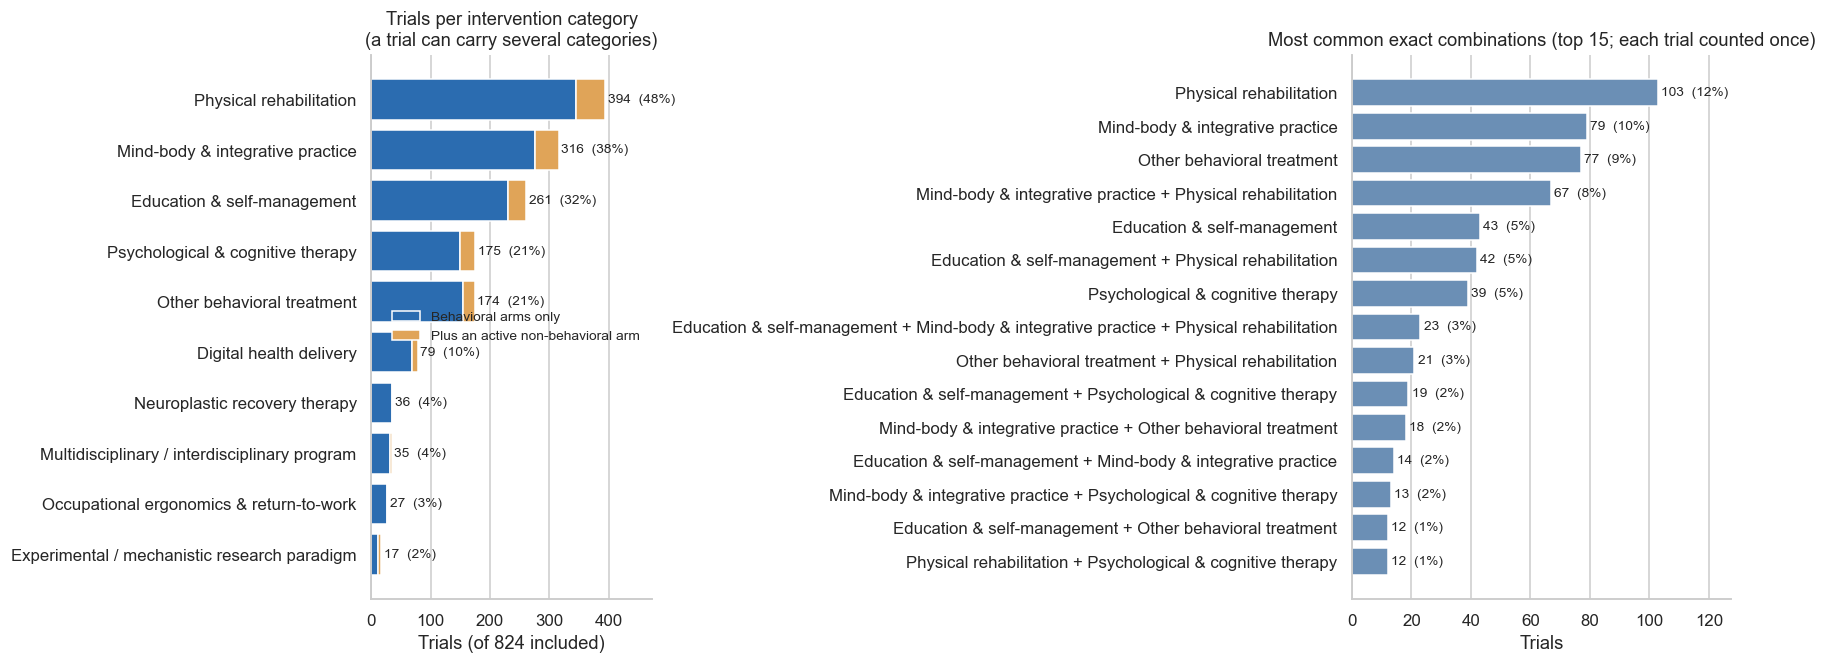

,trials,multimodal,share_of_included
category,,,
Physical rehabilitation,394,49,0.478
Mind-body & integrative practice,316,41,0.383
Education & self-management,261,31,0.317
Psychological & cognitive therapy,175,25,0.212
Other behavioral treatment,174,19,0.211
Digital health delivery,79,10,0.096
Neuroplastic recovery therapy,36,1,0.044
Multidisciplinary / interdisciplinary program,35,4,0.042
Occupational ergonomics & return-to-work,27,1,0.033


In [6]:
show(ap.plot_interventions(studies, LABELS), "fig05_interventions")
by_cat = (inc[["nct_id", "intervention_list", "is_multimodal"]].explode("intervention_list").dropna(subset=["intervention_list"])
          .assign(category=lambda d: d["intervention_list"].map(LABELS))
          .groupby("category").agg(trials=("nct_id", "nunique"), multimodal=("is_multimodal", "sum"))
          .sort_values("trials", ascending=False))
by_cat["share_of_included"] = (by_cat["trials"] / len(inc)).round(3)
ap.save_table(by_cat, "tab05_interventions")
display(by_cat)

## 6. Intervention category x outcome category

The main question of the study: which outcomes do trials of each intervention type register as primary?

* **Unit and double counting.** A trial with several intervention categories contributes its outcomes to **each** of them (use the sensitivity versions below for single-category trials).
* **Left panel (row share):** of all primary outcomes registered by the group, the share in each outcome category (each row sums to 100%). This is weighted by outcomes, so trials with many outcomes weigh more.
* **Right panel (trial share):** the share of the group's trials that registered **at least one** outcome of that category (columns do not sum to 100%; robust to trials with many outcomes).
* `not_an_outcome_measure` rows (baseline descriptors) are dropped; `other` is kept.
* Groups with fewer than 10 trials are marked `*` (unstable percentages).

### Filters
Edit the two queries and re-run the cell below; the filtered figure is saved as `fig06_custom`. `STUDY_FILTER` is a pandas query on the trial table, `OUTCOME_FILTER` on the outcome rows. Useful trial columns: `is_multimodal`, `n_intervention_categories`, `has_<category>` (e.g. `has_psychological_cognitive`), `eligible_back_pain` / `eligible_fibromyalgia` / `eligible_migraine` / `eligible_headache`, `n_conditions`, `first_post_year`, `period`, `raw_overall_status`, `raw_phases`, `raw_has_results`, `raw_primary_purpose`, `control_arm_types`, `n_primary_outcomes`. Outcome columns: `outcome_category`, `outcome_subcategory`, `outcome_category_review_flag`, `instruments_detected`, `n_primary_outcomes_in_study`. Examples: `"is_multimodal == False"`, `"eligible_migraine and not eligible_back_pain"`, `"first_post_year >= 2018"`.

In [7]:
# --- Edit and re-run: filters for the custom cross-tab (None = no filter) ---
STUDY_FILTER = None    # e.g. "is_multimodal == False"
OUTCOME_FILTER = None  # e.g. "outcome_category_review_flag == False"

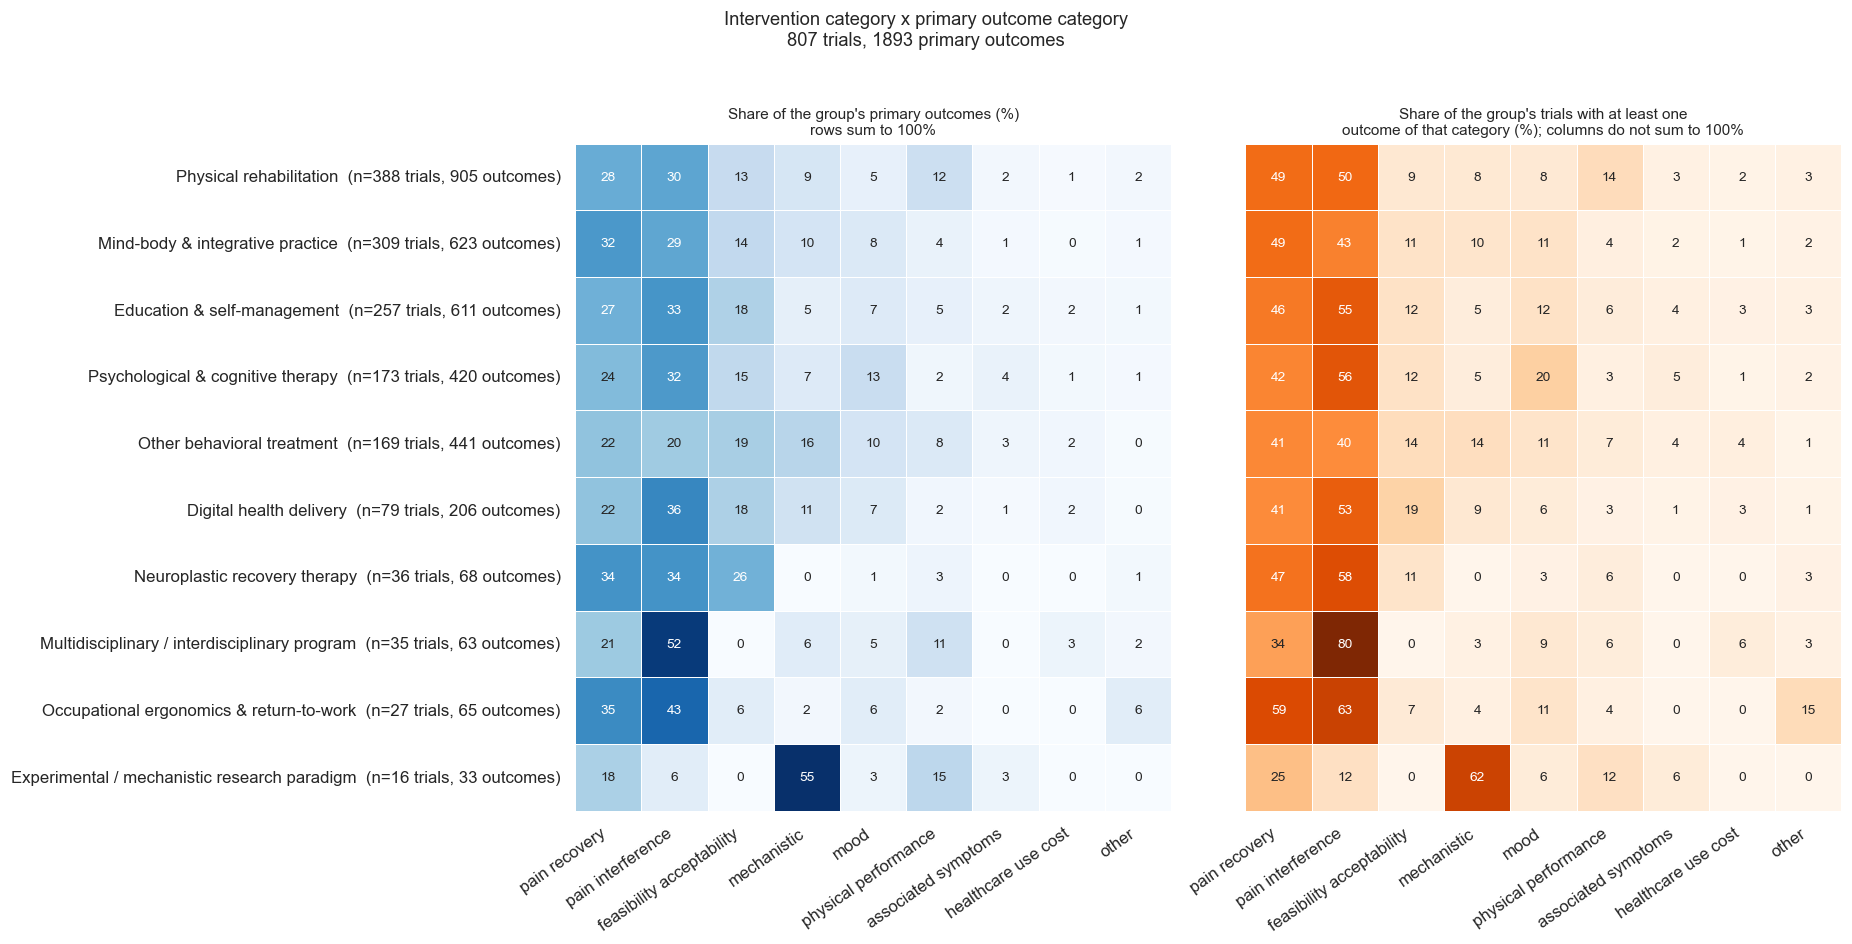

outcome_category,pain_recovery,pain_interference,feasibility_acceptability,mechanistic,mood,physical_performance,associated_symptoms,healthcare_use_cost,other,n_trials,n_outcomes
Physical rehabilitation,27.7,29.5,13.5,9.0,4.5,11.9,1.5,0.8,1.5,388,905
Mind-body & integrative practice,32.4,29.2,14.3,9.6,7.9,3.9,1.1,0.5,1.1,309,623
Education & self-management,26.8,33.4,17.5,4.9,7.2,4.6,2.5,1.6,1.5,257,611
Psychological & cognitive therapy,24.3,32.4,14.5,7.1,12.9,2.1,4.0,1.4,1.2,173,420
Other behavioral treatment,22.2,20.2,18.8,16.1,9.8,7.7,2.7,2.0,0.5,169,441
Digital health delivery,22.3,36.4,18.0,10.7,7.3,1.9,1.0,1.9,0.5,79,206
Neuroplastic recovery therapy,33.8,33.8,26.5,0.0,1.5,2.9,0.0,0.0,1.5,36,68
Multidisciplinary / interdisciplinary program,20.6,52.4,0.0,6.3,4.8,11.1,0.0,3.2,1.6,35,63
Occupational ergonomics & return-to-work,35.4,43.1,6.2,1.5,6.2,1.5,0.0,0.0,6.2,27,65
Experimental / mechanistic research paradigm,18.2,6.1,0.0,54.5,3.0,15.2,3.0,0.0,0.0,16,33


In [8]:
ct = ad.outcome_by_group(studies, outcomes, labels=LABELS)
show(ap.plot_crosstab(ct), "fig06_intervention_x_outcome")
ap.save_table(ct.row_percent().round(1), "tab06_intervention_x_outcome_row_percent")
ap.save_table(ct.trial_percent().round(1), "tab06_intervention_x_outcome_trial_percent")
ap.save_table(ct.rows, "tab06_intervention_x_outcome_rows_n")
ap.save_table(ct.trials, "tab06_intervention_x_outcome_trials_n")
display(ct.row_percent().round(1).assign(n_trials=ct.n_trials, n_outcomes=ct.n_rows))

In [9]:
if STUDY_FILTER or OUTCOME_FILTER:
    ct_custom = ad.outcome_by_group(studies, outcomes, labels=LABELS, study_query=STUDY_FILTER, outcome_query=OUTCOME_FILTER)
    title = f"Intervention category x outcome category | trials: {STUDY_FILTER or 'all'} | outcomes: {OUTCOME_FILTER or 'all'}"
    show(ap.plot_crosstab(ct_custom, title=title), "fig06_custom")
    ap.save_table(ct_custom.row_percent().round(1), "tab06_custom_row_percent")
else:
    print("No custom filter set (STUDY_FILTER / OUTCOME_FILTER above).")

No custom filter set (STUDY_FILTER / OUTCOME_FILTER above).


### Sensitivity versions (rebuilt every time)
Same cross-tab restricted to (a) trials with behavioral arms only, (b) trials with exactly one intervention category (no double counting), (c) completed trials.

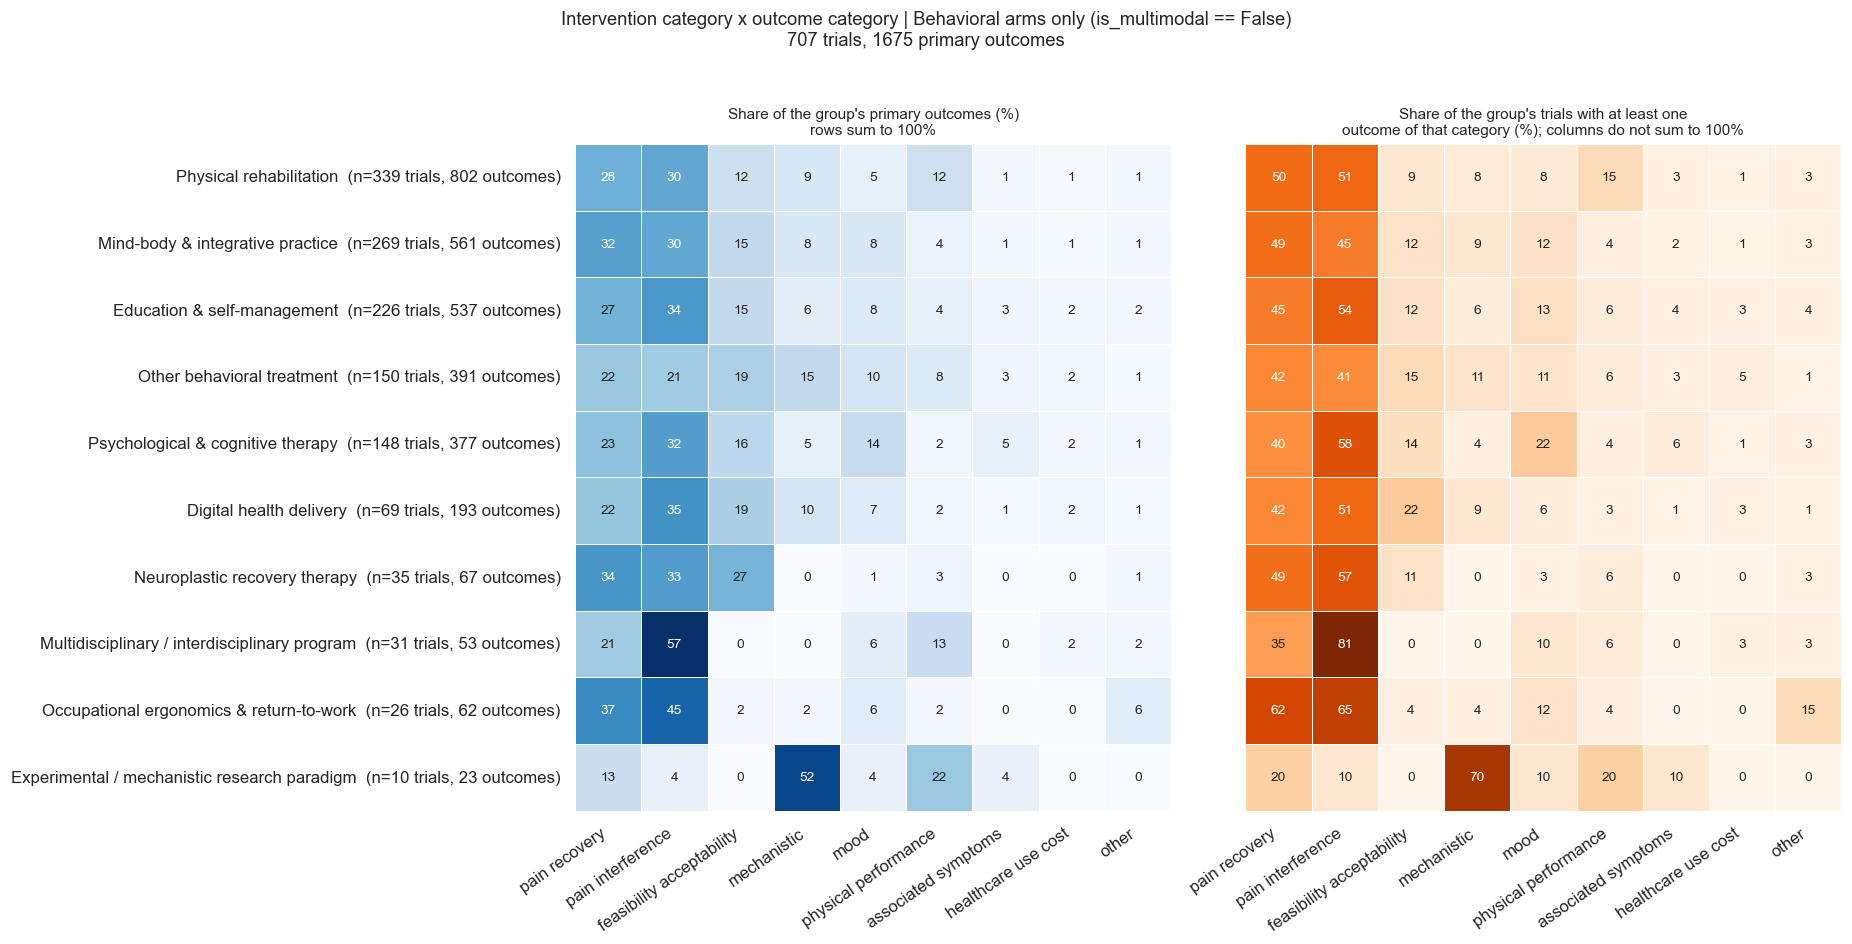

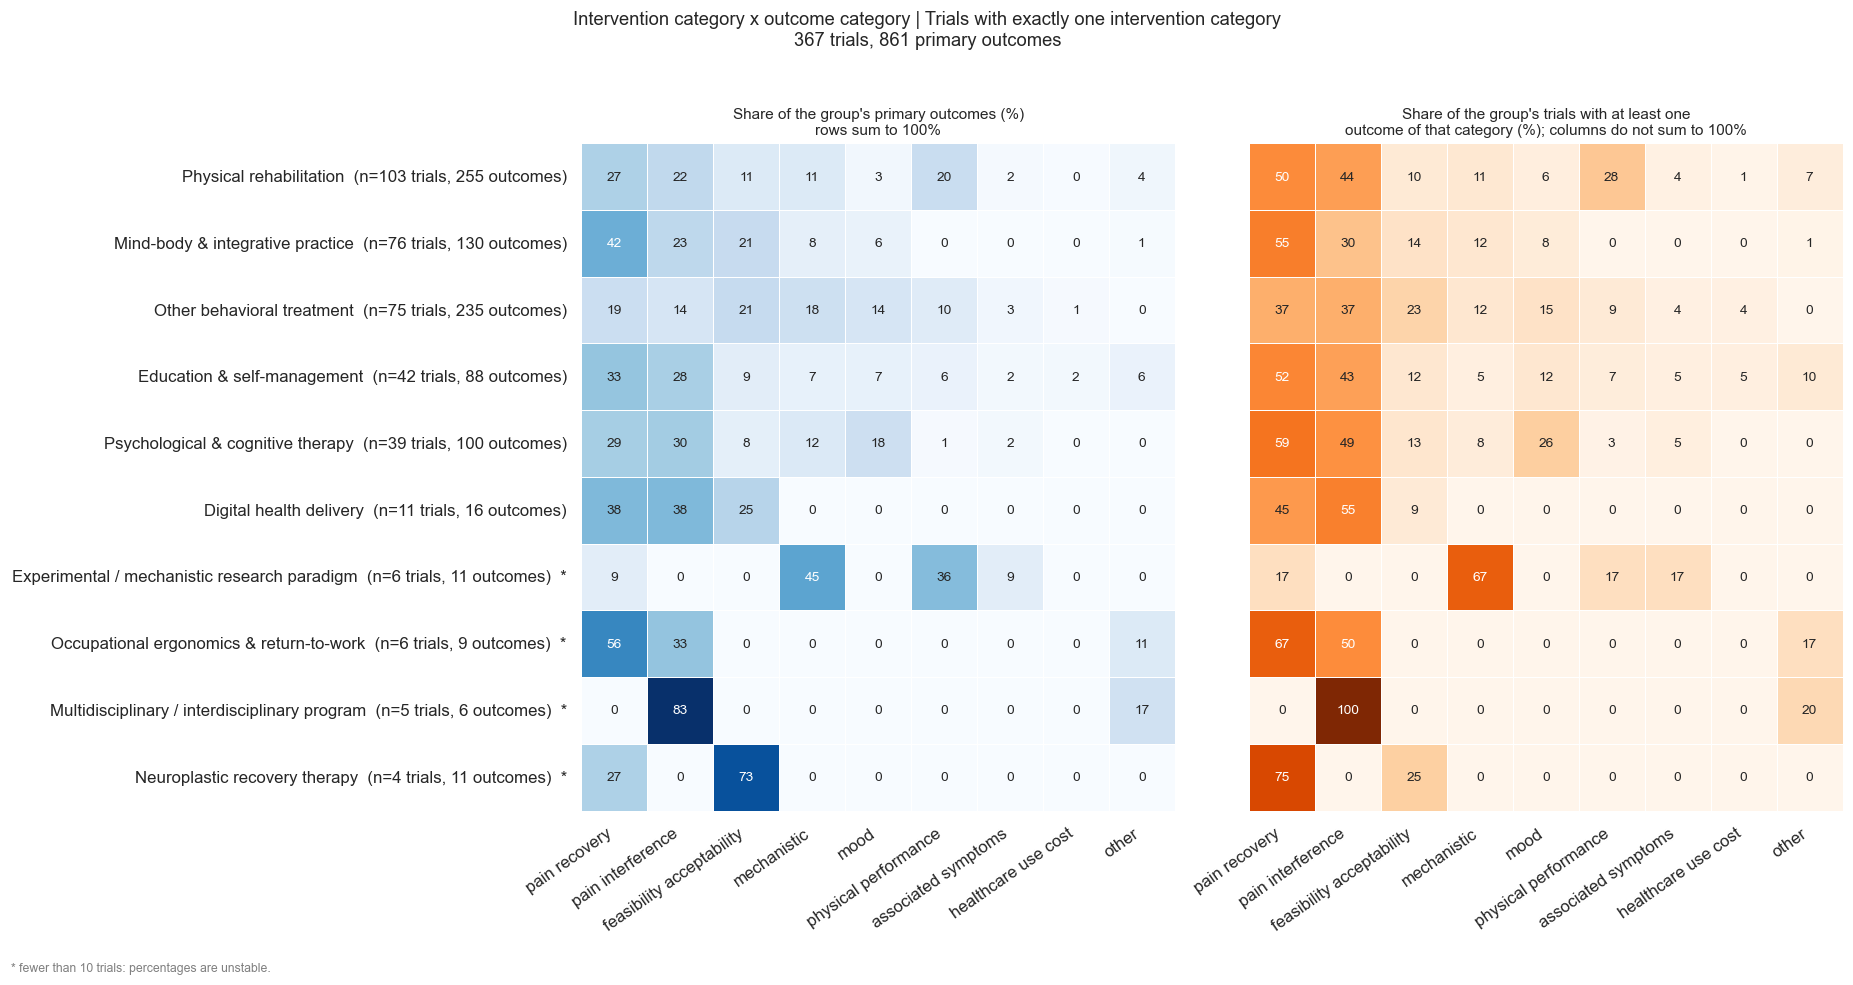

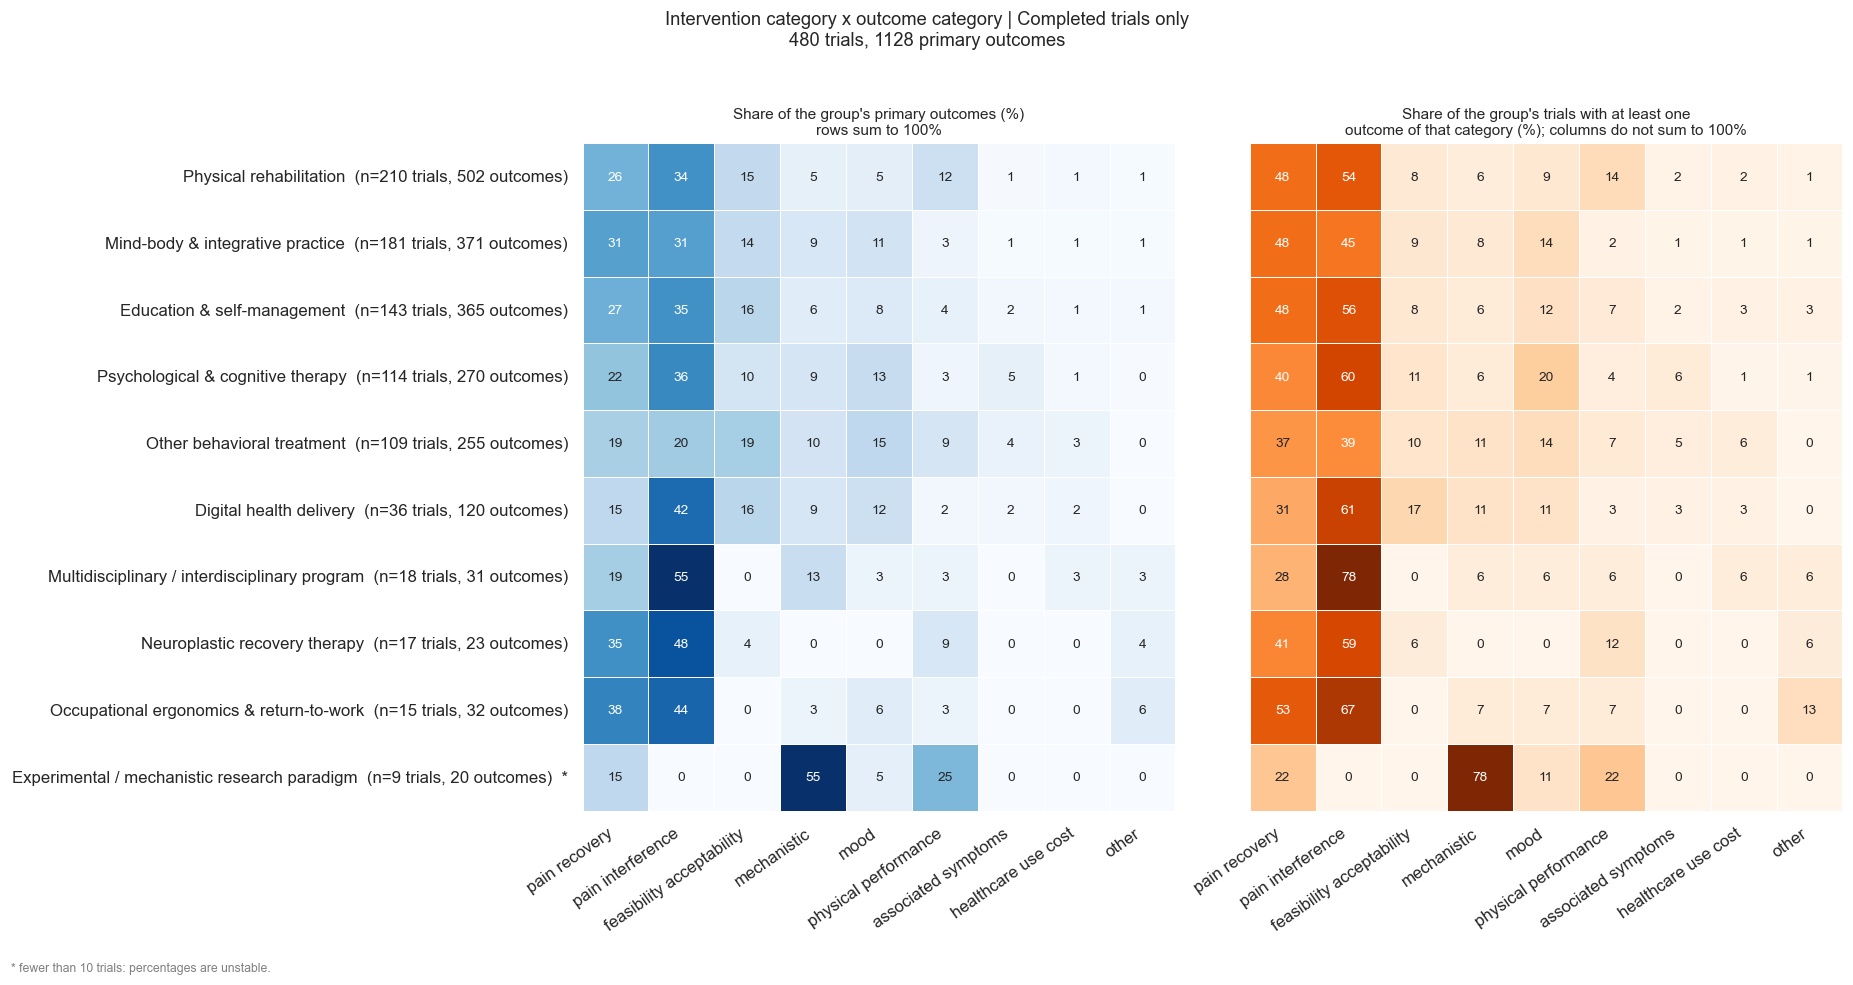

In [10]:
SENSITIVITY = {
    "unimodal": ("is_multimodal == False", "Behavioral arms only (is_multimodal == False)"),
    "single_category": ("n_intervention_categories == 1", "Trials with exactly one intervention category"),
    "completed": ("raw_overall_status == 'COMPLETED'", "Completed trials only"),
}
for key, (query, title) in SENSITIVITY.items():
    ct_s = ad.outcome_by_group(studies, outcomes, labels=LABELS, study_query=query)
    show(ap.plot_crosstab(ct_s, title=f"Intervention category x outcome category | {title}"), f"fig06_{key}")
    ap.save_table(ct_s.row_percent().round(1), f"tab06_{key}_row_percent")

## Additional views

### Outcome categories overall

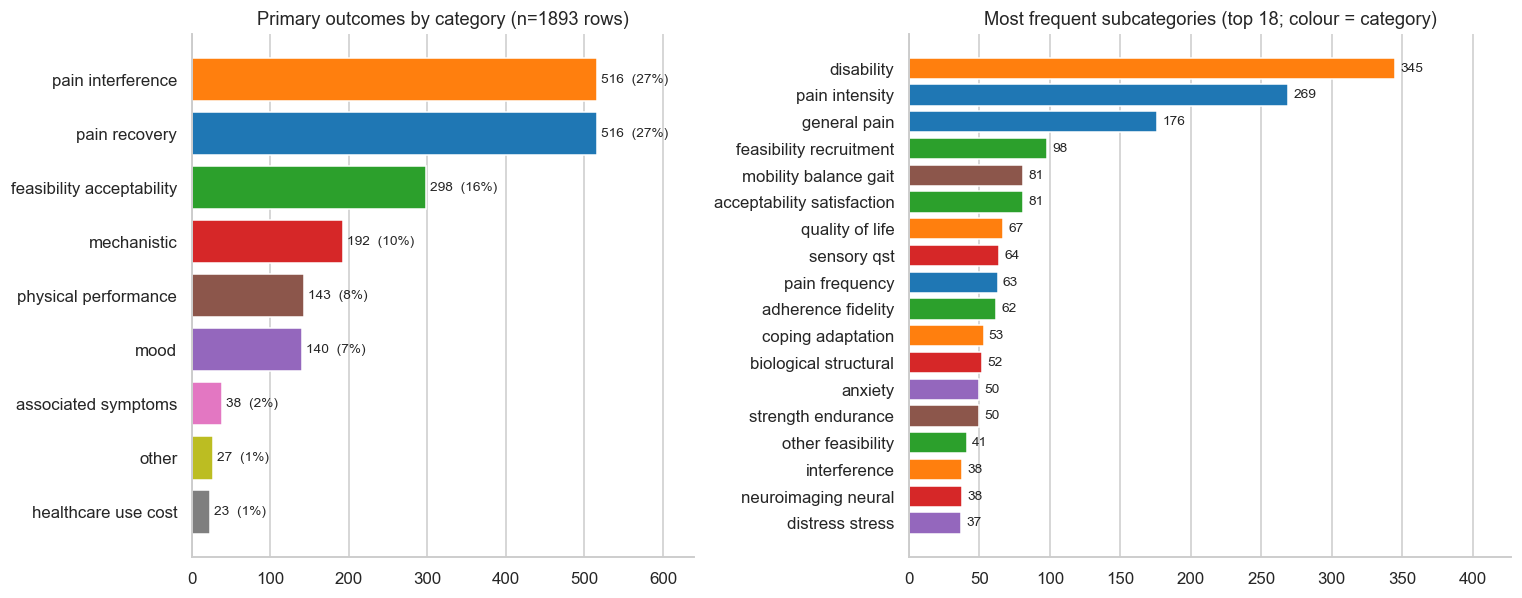

In [11]:
show(ap.plot_outcome_overview(outcomes), "fig07_outcome_overview")
overview = (outcomes[(outcomes["cohort_inclusion_status"] == "included")]
            .groupby(["outcome_category", "outcome_subcategory"]).agg(rows=("outcome_id", "size"), trials=("nct_id", "nunique")))
ap.save_table(overview, "tab07_outcome_overview")

### Outcome categories over time
Share of registered primary outcomes per category, by period of first posting (the research question's time dimension).

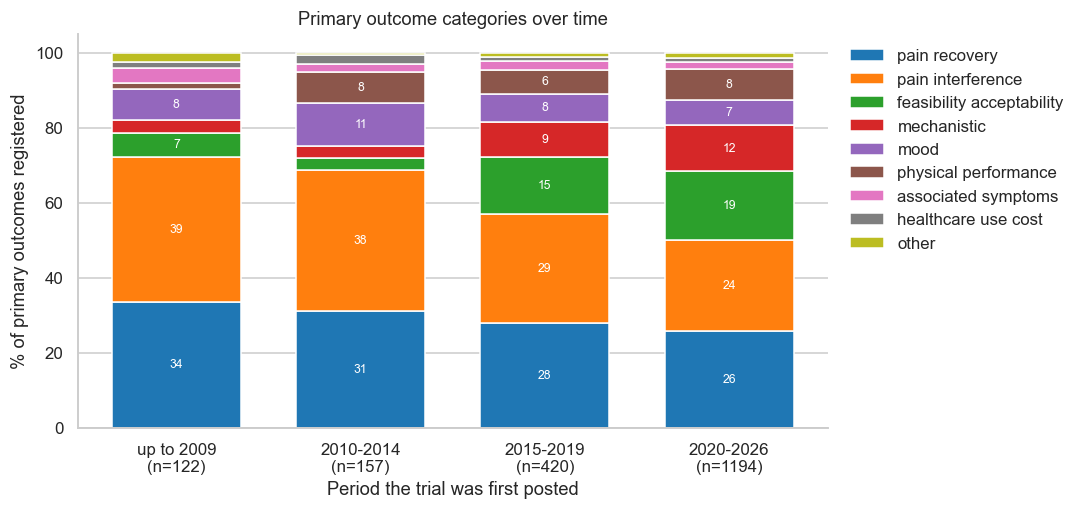

In [12]:
show(ap.plot_outcomes_over_time(studies, outcomes), "fig08_outcomes_over_time")

### Intervention categories over time

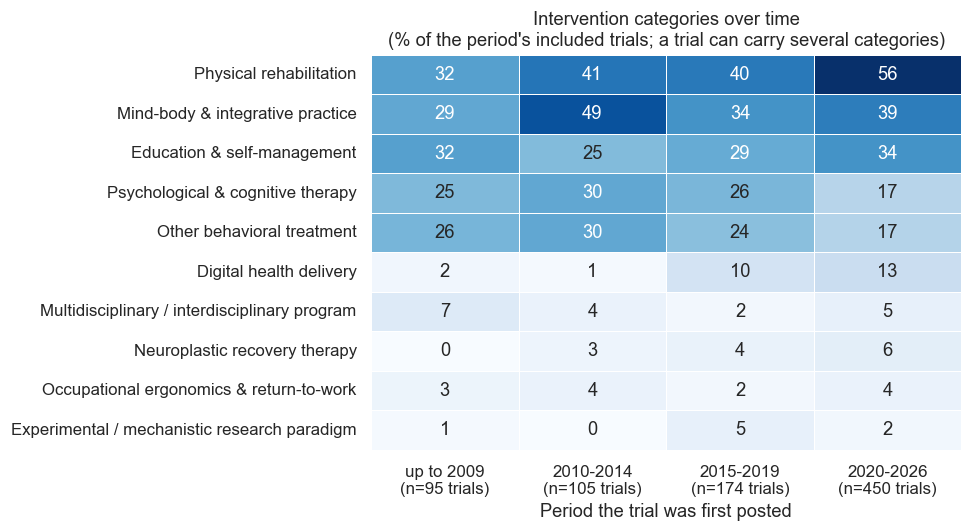

In [13]:
show(ap.plot_interventions_over_time(studies, LABELS), "fig09_interventions_over_time")

### Condition x outcome category
The same cross-tab with the pain condition as the group (a trial listing several conditions counts in each).

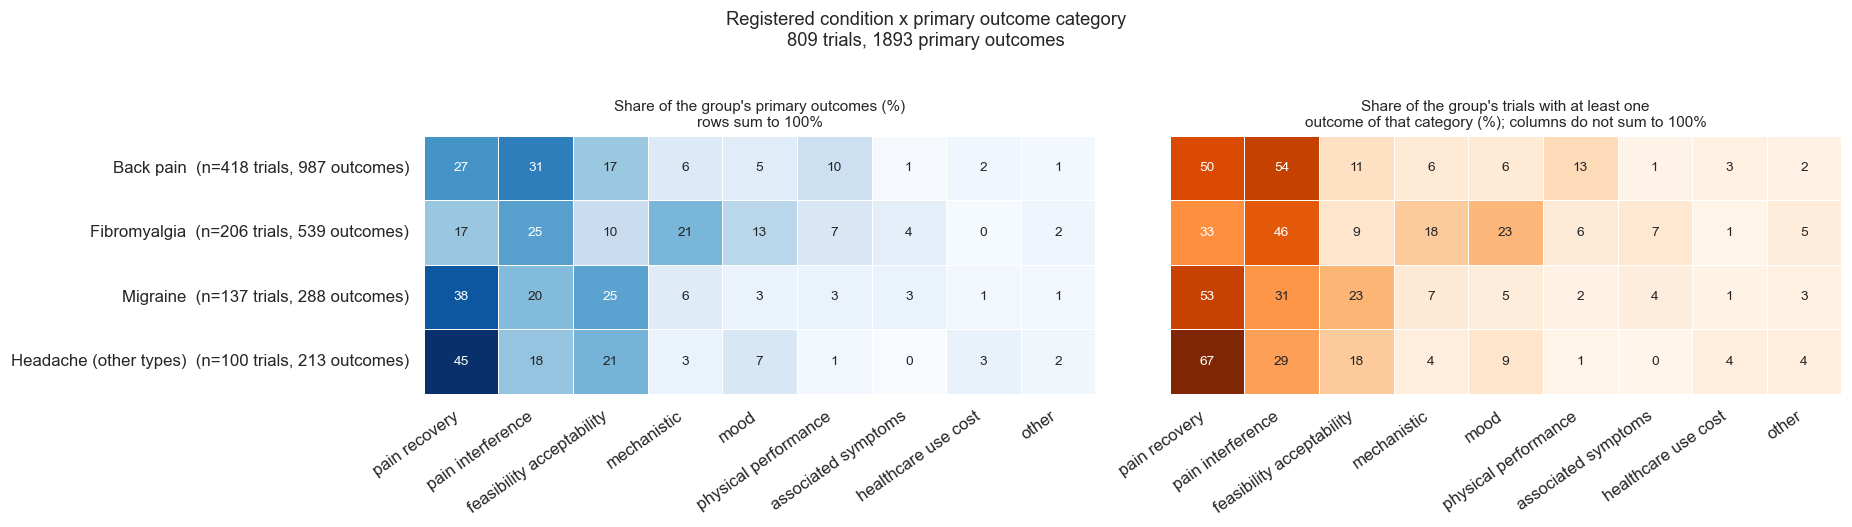

In [14]:
ct_cond = ad.outcome_by_group(studies, outcomes, group="condition_list")
show(ap.plot_crosstab(ct_cond, group_name="Condition", title="Registered condition x primary outcome category"), "fig10_condition_x_outcome")
ap.save_table(ct_cond.row_percent().round(1), "tab10_condition_x_outcome_row_percent")

### Instruments and number of primary outcomes per trial

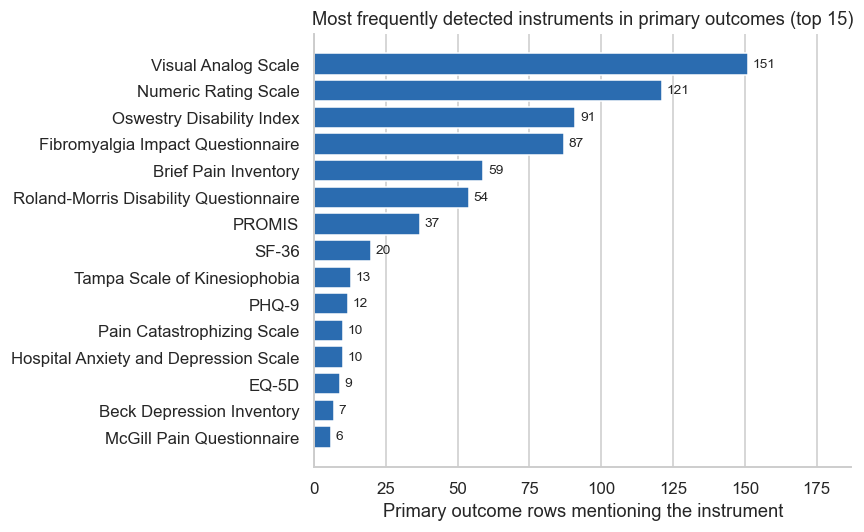

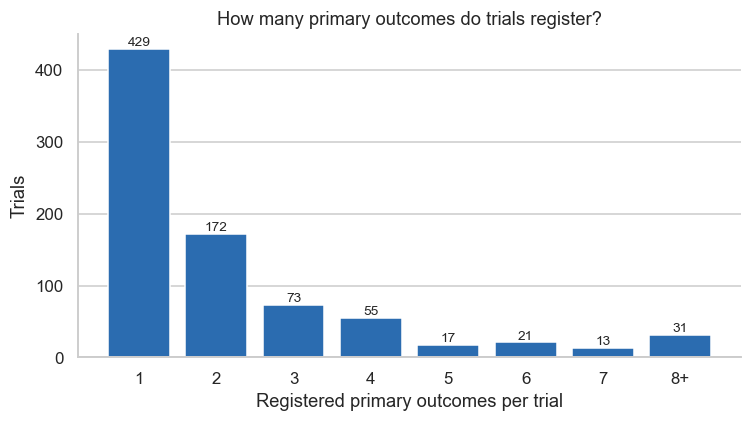

In [15]:
show(ap.plot_top_instruments(outcomes), "fig11_top_instruments")
show(ap.plot_outcomes_per_trial(studies), "fig12_outcomes_per_trial")

## Notes
* Cohort rules: `docs/COHORT_FILTERING_RULES.md`; category patterns and distributions: `docs/category_mapping.md`; columns: `docs/DATA_COLUMNS.md`.
* Outcome and intervention categories are rule-based, descriptive aids, not the researcher's manual conceptual coding; the raw outcome text is in `primary_outcomes.csv`.
* The year is the first-post date on ClinicalTrials.gov, not the trial's start date.